# **Length Profile**

Lengths of requests and answers before training the output-length estimator: which part of a long request the classifier should read (512-token limit), which value represents a length bucket, and whether Magpie and LMSYS-Chat-1M are similar in length to the request pool. LMSYS-Chat-1M is gated: accept its conditions on Hugging Face first.

## Install

In [ ]:
!pip install -q "transformers>=4.44" "datasets>=3.0" pyarrow

## Configuration

In [ ]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from transformers import AutoTokenizer

SEED = 42
REQUEST_POOL_PATH = "data/request_pool/request_pool_v2.parquet"
OUTPUT_DIR = "data/length_profile"

MAGPIE_REPO = "Magpie-Align/Magpie-Llama-3.1-Pro-300K-Filtered"   # same source as the Magpie part of the pool
LMSYS_REPO = "lmsys/lmsys-chat-1m"                                # gated: accept the conditions on its page
N_MAGPIE, N_LMSYS = 10_000, 10_000

COUNT_TOKENIZER = "meta-llama/Llama-3.1-8B-Instruct"   # answer lengths (same tokenizer as the pool)
CLASSIFIER_TOKENIZER = "distilbert-base-uncased"       # request lengths against the 512 limit
CLASSIFIER_LIMIT = 512 - 2                             # 2 places are taken by the special tokens [CLS] and [SEP]
TAIL_SHARE = 0.05                                      # tail weight: longest 5% of answers

## Token, request pool, tokenizers

In [ ]:
try:
    from google.colab import userdata                 # Colab: secret HF_TOKEN
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except ImportError:                                    # local run: environment variable or prompt
    from getpass import getpass
    os.environ["HF_TOKEN"] = os.environ.get("HF_TOKEN") or getpass("Hugging Face token: ")
HF_TOKEN = os.environ["HF_TOKEN"]
os.makedirs(OUTPUT_DIR, exist_ok=True)

pool = pd.read_parquet(REQUEST_POOL_PATH)
pool_texts = set(pool["text"].str.strip())
pool_magpie_ids = set(pool.loc[pool["source"] == "magpie", "source_index"].astype(str))
print(f"Request pool: {len(pool)} requests | with a realistic reference answer: {int(pool['reference_output_tokens'].notna().sum())}")

count_tok = AutoTokenizer.from_pretrained(COUNT_TOKENIZER, token=HF_TOKEN)
clf_tok = AutoTokenizer.from_pretrained(CLASSIFIER_TOKENIZER)

def n_tokens(tokenizer, texts, batch=256):
    out = []
    for s in range(0, len(texts), batch):
        out += [len(e) for e in tokenizer(list(texts[s:s + batch]), add_special_tokens=False)["input_ids"]]
    return np.array(out)

Mounted at /content/drive
Request pool: 5042 requests | with a realistic reference answer: 2932


config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

## Statistics function

`over_limit`: share of requests longer than the classifier can read (510 text tokens). `tail_weight`: share of all answer tokens that comes from the longest 5% of answers.

In [ ]:
def length_stats(values):
    v = np.sort(np.asarray(values, dtype=float))
    v = v[~np.isnan(v)]
    if len(v) == 0:
        return {}
    k = max(1, int(np.ceil(TAIL_SHARE * len(v))))
    return {"n": len(v), "mean": v.mean(), "median": np.median(v), "p90": np.quantile(v, .9),
            "p99": np.quantile(v, .99), "max": v.max(), "tail_weight": v[-k:].sum() / v.sum()}

def stats_table(df, value_col, group_col):
    rows = {g: length_stats(d[value_col]) for g, d in df.groupby(group_col)}
    rows["ALL"] = length_stats(df[value_col])
    t = pd.DataFrame(rows).T
    for c in ["n", "mean", "median", "p90", "p99", "max"]:
        t[c] = t[c].round(0).astype(int)
    t["tail_weight"] = (100 * t["tail_weight"]).round(1).astype(str) + "%"
    return t

## Request pool: request length

In [ ]:
pool["input_tokens_clf"] = n_tokens(clf_tok, pool["text"].tolist())
pool["over_limit"] = pool["input_tokens_clf"] > CLASSIFIER_LIMIT

t5 = stats_table(pool, "input_tokens_clf", "source")
t5["over_limit"] = (100 * pool.groupby("source")["over_limit"].mean()).round(1).astype(str) + "%"
t5.loc["ALL", "over_limit"] = f"{100 * pool['over_limit'].mean():.1f}%"
print("Request length, DistilBERT tokens, per source")
print(t5.drop(columns="tail_weight").to_string())
print(f"\nRequests over {CLASSIFIER_LIMIT} DistilBERT tokens: {int(pool['over_limit'].sum())} of {len(pool)}")
print("\nThe same requests, by task:")
over = pool[pool["over_limit"]]
print(over.groupby(["source", "task"]).size().rename("requests").to_string() if len(over) else "none")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (516 > 512). Running this sequence through the model will result in indexing errors


Request length, DistilBERT tokens, per source
                 n   mean  median     p90     p99     max over_limit
dolly          300    120      30     236     705    5344       3.0%
longbench_v1   450   8619    7642   15332   21538   27437      99.8%
longbench_v2   273  59416   45566  126829  135788  140386     100.0%
magpie        1932    136      68     346     848    1269       5.0%
math           250     70      45     132     488     691       0.8%
routerarena   1587    280     104     812    1766    4559      18.7%
taco           250    529     498     809    1235    1362      48.0%
ALL           5042   4164     111    7545  102050  140386      24.7%

Requests over 510 DistilBERT tokens: 1245 of 5042

The same requests, by task:
source        task                  
dolly         information_extraction      1
              qa                          3
              summarization               5
longbench_v1  in_context_learning       150
              long_document_qa          

## Request pool: reference answer length

In [ ]:
ref = pool[pool["reference_output_tokens"].notna()]
t6 = stats_table(ref, "reference_output_tokens", "source")
print("Reference answer length, Llama-3.1 tokens, per source")
print(t6.to_string())
print("\nBy source and task:")
print(stats_table(ref.assign(source_task=ref["source"] + " / " + ref["task"]), "reference_output_tokens", "source_task")[["n", "median", "p90", "max"]].to_string())

Reference answer length, Llama-3.1 tokens, per source
                 n  mean  median  p90   p99    max tail_weight
dolly          300    95      50  195   684   1661       33.4%
longbench_v1   150   341     302  796   942   1416       15.3%
magpie        1932   567     523  815  1325   4070       11.4%
math           250   172     130  321   883   1363       20.9%
routerarena     50    81      53  190   286    315       19.8%
taco           250   381     210  648  3642  14689       38.2%
ALL           2932   449     433  766  1298  14689       15.0%

By source and task:
                                   n  median  p90    max
dolly / brainstorming             50      48  152    544
dolly / classification            50      28   94    207
dolly / creative_writing          50     148  366   1661
dolly / information_extraction    50      26   59    388
dolly / qa                        50      44  191    680
dolly / summarization             50      68  162   1113
longbench_v1 / summari

## Candidate training sets

Magpie examples not in the pool; LMSYS-Chat-1M English conversations, first turn only.

In [ ]:
def take(stream, n, keep):
    rows = []
    for ex in stream:
        r = keep(ex)
        if r is not None:
            rows.append(r)
            if len(rows) == n:
                break
    return pd.DataFrame(rows)

def keep_magpie(ex):
    if str(ex.get("uuid")) in pool_magpie_ids or str(ex["instruction"]).strip() in pool_texts:
        return None
    return {"text": ex["instruction"], "answer": ex["response"], "origin": "magpie (external)"}

def keep_lmsys(ex):
    conv = ex.get("conversation") or []
    if ex.get("language") != "English" or len(conv) < 2 or conv[0].get("role") != "user" or conv[1].get("role") != "assistant":
        return None
    text, answer = conv[0].get("content", ""), conv[1].get("content", "")
    if not text.strip() or not answer.strip() or text.strip() in pool_texts:
        return None
    return {"text": text, "answer": answer, "origin": "lmsys (external)"}

magpie = take(load_dataset(MAGPIE_REPO, split="train", streaming=True, token=HF_TOKEN).shuffle(seed=SEED, buffer_size=20_000), N_MAGPIE, keep_magpie)
lmsys = take(load_dataset(LMSYS_REPO, split="train", streaming=True, token=HF_TOKEN).shuffle(seed=SEED, buffer_size=20_000), N_LMSYS, keep_lmsys)
ext = pd.concat([magpie, lmsys], ignore_index=True)
ext["input_tokens_clf"] = n_tokens(clf_tok, ext["text"].tolist())
ext["output_tokens"] = n_tokens(count_tok, ext["answer"].tolist())
ext["over_limit"] = ext["input_tokens_clf"] > CLASSIFIER_LIMIT
print(f"Magpie: {len(magpie)} | LMSYS-Chat-1M: {len(lmsys)}")

Magpie: 10000 | LMSYS-Chat-1M: 10000


## Comparison: answer length, pool vs candidate training sets

In [ ]:
both = pd.concat([
    ref.assign(group="pool / " + ref["source"], output_tokens=ref["reference_output_tokens"])[["group", "output_tokens"]],
    ext.assign(group=ext["origin"])[["group", "output_tokens"]],
], ignore_index=True)
t8 = stats_table(both, "output_tokens", "group").drop(index="ALL")
print("Answer length, Llama-3.1 tokens")
print(t8.to_string())

t8b = stats_table(ext, "input_tokens_clf", "origin").drop(columns="tail_weight")
t8b["over_limit"] = (100 * ext.groupby("origin")["over_limit"].mean()).round(1).astype(str) + "%"
t8b.loc["ALL", "over_limit"] = f"{100 * ext['over_limit'].mean():.1f}%"
print("\nRequest length of the candidate training sets, DistilBERT tokens")
print(t8b.to_string())

Answer length, Llama-3.1 tokens
                         n  mean  median  p90   p99    max tail_weight
lmsys (external)     10000   179     126  418   710   2086       16.7%
magpie (external)    10000   617     541  835  3909   4071       16.2%
pool / dolly           300    95      50  195   684   1661       33.4%
pool / longbench_v1    150   341     302  796   942   1416       15.3%
pool / magpie         1932   567     523  815  1325   4070       11.4%
pool / math            250   172     130  321   883   1363       20.9%
pool / routerarena      50    81      53  190   286    315       19.8%
pool / taco            250   381     210  648  3642  14689       38.2%

Request length of the candidate training sets, DistilBERT tokens
                       n  mean  median  p90  p99   max over_limit
lmsys (external)   10000    86      29  278  627  1228       2.7%
magpie (external)  10000   106      63  237  723  1283       2.5%
ALL                20000    96      47  257  656  1283       2.6%

## Histograms

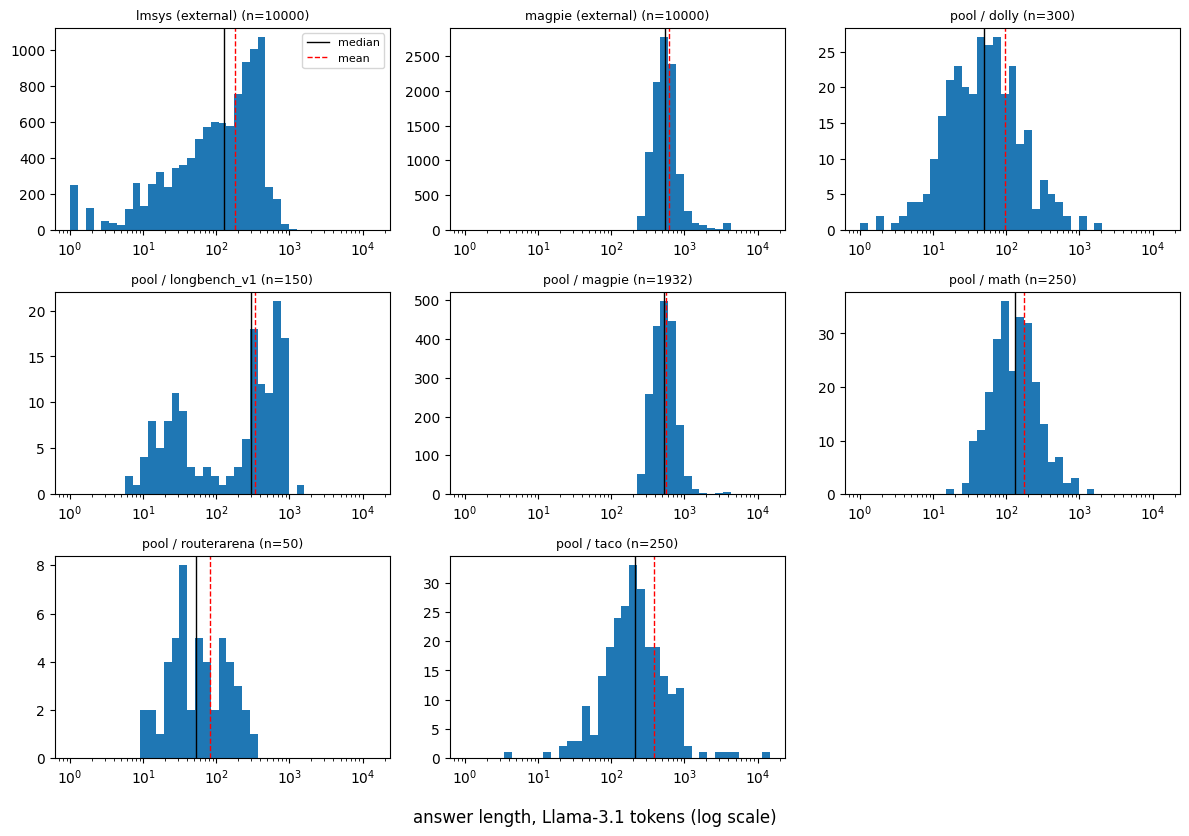

In [ ]:
groups = list(t8.index)
cols = 3
rows = int(np.ceil(len(groups) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 2.8 * rows), squeeze=False)
bins = np.logspace(0, np.log10(max(10, both["output_tokens"].max())), 40)
for ax, g in zip(axes.flat, groups):
    v = both.loc[both["group"] == g, "output_tokens"]
    ax.hist(v.clip(lower=1), bins=bins)
    ax.axvline(v.median(), color="black", lw=1, label="median")
    ax.axvline(v.mean(), color="red", lw=1, ls="--", label="mean")
    ax.set_xscale("log")
    ax.set_title(f"{g} (n={len(v)})", fontsize=9)
for ax in list(axes.flat)[len(groups):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=8)
fig.supxlabel("answer length, Llama-3.1 tokens (log scale)")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "answer_length_histograms.png"), dpi=120)
plt.show()

## Save

In [ ]:
t5.to_csv(os.path.join(OUTPUT_DIR, "pool_request_length.csv"))
t6.to_csv(os.path.join(OUTPUT_DIR, "pool_reference_length.csv"))
t8.to_csv(os.path.join(OUTPUT_DIR, "answer_length_comparison.csv"))
t8b.to_csv(os.path.join(OUTPUT_DIR, "external_request_length.csv"))
print("Saved in", OUTPUT_DIR)

Saved in /content/drive/MyDrive/thesis/length_profile


In [ ]:
# check: Magpie answers close to 4,000 tokens (possibly cut at the generation limit)
LONG = 3900   # Llama-3.1 tokens; the generation limit is 4,096

def repeated_line_share(text):
    # share of non-empty lines that are exact repeats of an earlier line (0 = no repetition)
    lines = [l.strip() for l in text.splitlines() if l.strip()]
    return 0.0 if not lines else 1 - len(set(lines)) / len(lines)

def ends_cleanly(text):
    # True if the answer ends like a finished sentence or a closed code block
    return text.rstrip()[-1:] in {".", "!", "?", "`", ")", "]", "\"", "*"}

mag = ext[ext["origin"] == "magpie (external)"].copy()
mag["long"] = mag["output_tokens"] >= LONG
mag["repeated_lines"] = mag["answer"].map(repeated_line_share)
mag["ends_cleanly"] = mag["answer"].map(ends_cleanly)

print(f"External Magpie: {int(mag['long'].sum())} of {len(mag)} answers >= {LONG} tokens "
      f"({100 * mag['long'].mean():.1f}%)")
pool_long = (pool.loc[pool["source"] == "magpie", "reference_output_tokens"] >= LONG).sum()
print(f"Pool Magpie: {int(pool_long)} of {int((pool['source'] == 'magpie').sum())} reference answers >= {LONG} tokens")

print("\nLong vs other answers (external Magpie):")
print(mag.groupby("long")[["output_tokens", "repeated_lines", "ends_cleanly"]].mean().round(2).to_string())

print("\nThree long answers: first and last 400 characters")
for _, r in mag[mag["long"]].sample(min(3, int(mag["long"].sum())), random_state=SEED).iterrows():
    print("=" * 100)
    print(f"tokens: {r['output_tokens']} | repeated lines: {r['repeated_lines']:.0%} | ends cleanly: {r['ends_cleanly']}")
    print("REQUEST:", r["text"][:300].replace("\n", " "))
    print("--- answer, beginning ---\n" + r["answer"][:400])
    print("--- answer, end ---\n" + r["answer"][-400:])

External Magpie: 101 of 10000 answers >= 3900 tokens (1.0%)
Pool Magpie: 3 of 1932 reference answers >= 3900 tokens

Long vs other answers (external Magpie):
       output_tokens  repeated_lines  ends_cleanly
long                                              
False         582.29            0.02          0.63
True         4024.73            0.20          0.05

Three long answers: first and last 400 characters
tokens: 3995 | repeated lines: 7% | ends cleanly: False
REQUEST: Anne tells her three friends Bob, Charlie, and David to each walk $\mathop{x}$ miles. The distances they walk form an arithmetic sequence, i.e., $x$, $x + d$, and $x + 2d$ miles. Further, she tells them that the sum of the squares of their distances is 100h, and that the product of their distances i
--- answer, beginning ---
## Step 1: Express the sum of the squares of the distances in terms of x and d
The sum of the squares of their distances can be expressed as $x^2 + (x + d)^2 + (x + 2d)^2 = 100h$.

## Step 2: Exp

In [ ]:
# check: pool references of 3,900 tokens or more, by source
long_ref = pool[pool["reference_output_tokens"] >= LONG]
print(long_ref.groupby("source").size().rename("references >= 3900").to_string())

ref_col = "reference_output" if "reference_output" in pool.columns else None
if ref_col is None:
    print("The pool stores only the length of the references, not their text: cannot inspect them.")
else:
    for _, r in long_ref.iterrows():
        txt = str(r[ref_col])
        print("=" * 100)
        print(f"{r['source']} | {r['task']} | tokens: {int(r['reference_output_tokens'])} | "
              f"repeated lines: {repeated_line_share(txt):.0%} | ends cleanly: {ends_cleanly(txt)}")
        print("REQUEST:", str(r["text"])[:300].replace("\n", " "))
        print("--- reference, beginning ---\n" + txt[:400])
        print("--- reference, end ---\n" + txt[-400:])

source
magpie    3
taco      3
The pool stores only the length of the references, not their text: cannot inspect them.


In [ ]:
# check: text of the pool Magpie references of 3,900 tokens or more (from the original dataset)
ids = set(pool.loc[(pool["source"] == "magpie") & (pool["reference_output_tokens"] >= LONG), "source_index"].astype(str))
found = {}
for ex in load_dataset(MAGPIE_REPO, split="train", streaming=True, token=HF_TOKEN):
    if str(ex.get("uuid")) in ids:
        found[str(ex["uuid"])] = ex["response"]
        if len(found) == len(ids):
            break
print(f"Found {len(found)} of {len(ids)}")
for uid, txt in found.items():
    print("=" * 100)
    print(f"{uid} | repeated lines: {repeated_line_share(txt):.0%} | ends cleanly: {ends_cleanly(txt)}")
    print("--- end ---\n" + txt[-400:])

Found 3 of 3
413dc045-ff45-5775-8250-061bd2e82f61 | repeated lines: 72% | ends cleanly: True
--- end ---
.. no...

A possible rearrangement is: "T-R-I-E-D" becomes "D-E-R-T-I" ... no...

A possible rearrangement is: "T-R-I-E-D" becomes "R-E-D-I-T" ... no...

A possible rearrangement is: "T-R-I-E-D" becomes "R-T-E-D-I" ... no...

A possible rearrangement is: "T-R-I-E-D" becomes "R-E-T-I-D" ... no...

A possible rearrangement is: "T-R-I-E-D" becomes "D-R-E-I-T" ... no...

A possible rearrangement is: "
3712f06a-ac65-50f1-9f36-9017a9d712eb | repeated lines: 0% | ends cleanly: False
--- end ---
ging gives x - 2x = 32 - 22, simplifying to -x = 10. Solving for x correctly gives x = 10 years, but due to the error in algebra, the correct solution is different.

## Step 11: Correctly solve the equation.
22 + x = 32 + 2x. Rearrange the equation to get x - 2x = 32 - 22, simplifying to -x = 10. Solving for x correctly should give a positive number of years. Correctly solving for x: 22 + x = 32 +
1

In [ ]:
# check: generation settings stored in Magpie (is there a max_tokens limit?)
ex = next(iter(load_dataset(MAGPIE_REPO, split="train", streaming=True, token=HF_TOKEN)))
print([k for k in ex.keys()])
for k in ex:
    if "config" in k:
        print(k, "->", ex[k])

['uuid', 'model', 'gen_input_configs', 'instruction', 'response', 'conversations', 'task_category', 'other_task_category', 'task_category_generator', 'difficulty', 'intent', 'knowledge', 'difficulty_generator', 'input_quality', 'quality_explanation', 'quality_generator', 'llama_guard_2', 'reward_model', 'instruct_reward', 'min_neighbor_distance', 'repeat_count', 'min_similar_uuid', 'instruction_length', 'response_length', 'language']
gen_input_configs -> {'temperature': 0.9, 'top_p': 1.0, 'input_generator': 'meta-llama/Meta-Llama-3.1-70B-Instruct', 'seed': None, 'pre_query_template': '<|begin_of_text|><|start_header_id|>user<|end_header_id|>\n\n'}
